# Tarea 1: Problemas de Regresión — Daily Demand Forecasting Orders

**Curso:** Aprendizaje Automático — Universidad Autónoma de Occidente  
**Integrantes:** David Alberto Vergara Tabares, Sebastián Giraldo Acosta, Violeta Isabella España Bolaños, Murillo

## Introducción

El dataset **Daily Demand Forecasting Orders** (repositorio UCI) contiene 60 días de pedidos de una empresa de logística en Brasil. Cada fila es un día y registra cuántos pedidos llegaron por tipo (urgentes, no urgentes, tipos A, B y C) y por sector (fiscal, control de tráfico y tres sectores bancarios), además de la semana del mes y el día de la semana.

**Objetivo:** predecir el total de pedidos del día, `Target (Total orders)`, con un modelo de regresión lineal.

## Análisis exploratorio de datos (EDA)

En esta sección se cargan los datos, se revisa su calidad y se analiza la relación de cada variable con el Target para decidir qué variables estimadoras usar en el modelo.

### 1. Librerías y configuración

Se importan las librerías del análisis: **NumPy** para cálculos numéricos, **pandas** para manejar la tabla de datos, **matplotlib** y **seaborn** para las gráficas y **scipy.stats** para pruebas estadísticas.

Se fija una semilla (`SEMILLA = 42`) para que cualquier proceso aleatorio, como la división entre entrenamiento y validación, dé el mismo resultado en cada ejecución. También se define la función `resumen(df)`, que genera una ficha técnica de cada columna.

In [1]:
# ---------------------------------------------------------------
# Librerías
# ---------------------------------------------------------------
import numpy as np               # Cálculos numéricos con vectores y matrices (se usará en la Ecuación Normal y el gradiente descendente)
import pandas as pd              # Manejo de tablas de datos (DataFrame): leer el CSV, filtrar, calcular estadísticas
import matplotlib.pyplot as plt  # Librería base para hacer gráficas
import seaborn as sns            # Gráficas estadísticas más completas (heatmap, regplot) construidas sobre matplotlib
from scipy import stats          # Funciones estadísticas (pruebas, z-score); disponible para el análisis de outliers

# ---------------------------------------------------------------
# Semilla
# ---------------------------------------------------------------
# Algunos procesos usan números aleatorios (por ejemplo, la división entre
# entrenamiento y validación). Fijar la semilla hace que siempre salgan
# los mismos números, así cualquiera que ejecute el notebook obtiene
# exactamente los mismos resultados.
SEMILLA = 42
np.random.seed(SEMILLA)


# ---------------------------------------------------------------
# Función de apoyo: ficha técnica del dataset
# ---------------------------------------------------------------
def resumen(df):
    """Ficha técnica por columna: tipo, nulos, valores únicos y un ejemplo."""
    # Construye una tabla donde cada fila es una columna del dataset
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),                  # Tipo de dato: int64 (entero), float64 (decimal), object (texto)
        "no_nulos": df.notna().sum(),                   # Cuántos valores sí tienen dato
        "nulos": df.isna().sum(),                       # Cuántos valores están vacíos (NaN)
        "%_nulos": (df.isna().mean() * 100).round(2),   # Porcentaje de vacíos: si es alto habría que imputar o eliminar
        "valores_unicos": df.nunique(),                 # Cuántos valores distintos hay: pocos indica variable categórica
        "ejemplo": df.iloc[0],                          # Valor de la primera fila, para ver cómo luce el dato
    })

### 1.2 Carga y revisión de los datos

Se lee el archivo CSV original de UCI (separado por `;`) desde la carpeta `dataset/` y se muestran sus dimensiones, las primeras filas y la ficha técnica de cada columna.

**Resultado:** el dataset tiene **60 filas y 13 columnas** (12 predictoras y el Target), todas numéricas, **sin valores nulos**. `Week of the month` y `Day of the week` son categorías codificadas como números (semana 1–5; día 2 = lunes a 6 = viernes).

In [10]:
RUTA_DATOS = "dataset/Daily_Demand_Forecasting_Orders.csv"  # Ruta relativa al archivo CSV del dataset

df = pd.read_csv(RUTA_DATOS, sep=";")      # Lee el archivo CSV indicando que el separador es punto y coma
df = df.dropna(axis=1, how="all")          # Elimina columnas que estén completamente vacías

# Renombra las dos primeras columnas para acortarlas y corregir el paréntesis sin cerrar
df = df.rename(columns={
    df.columns[0]: "Week of the month",    # Columna 0 -> Semana del mes (1 a 5)
    df.columns[1]: "Day of the week"       # Columna 1 -> Día de la semana (2=Lunes a 6=Viernes)
})

# Pasa a miles (/ 1000) las 4 columnas que venían en unidades enteras para unificar la escala
cols_en_unidades = [
    "Orders from the traffic controller sector",
    "Banking orders (1)",
    "Banking orders (2)",
    "Banking orders (3)",
]
df[cols_en_unidades] = df[cols_en_unidades] / 1000.0  # Ej: 188411 pasa a 188.411 (miles de pedidos)

# Corrige también los 11 registros de Fiscal sector orders que se guardaron en unidades sin punto decimal
mask_fiscal = (df["Non-urgent order"] + df["Urgent order"] + df["Fiscal sector orders"] - df["Target (Total orders)"]).abs() > 1
df.loc[mask_fiscal, "Fiscal sector orders"] = df.loc[mask_fiscal, "Fiscal sector orders"] / 1000.0

print(f"Dimensiones: {df.shape} | Filas duplicadas: {df.duplicated().sum()}")  # Imprime (filas, columnas) y duplicados
display(df.head())                         # Muestra las primeras 5 filas ya en la misma escala de miles
display(resumen(df))                       # Muestra la ficha técnica por columna




Dimensiones: (60, 13) | Filas duplicadas: 0


,Week of the month,Day of the week,Non-urgent order,Urgent order,Order type A,Order type B,Order type C,Fiscal sector orders,Orders from the traffic controller sector,Banking orders (1),Banking orders (2),Banking orders (3),Target (Total orders)
0,1,4,316.307,223.270,61.543,175.586,302.448,0.000,65.556,44.914,188.411,14.793,539.577
1,1,5,128.633,96.042,38.058,56.037,130.580,0.000,40.419,21.399,89.461,7.679,224.675
2,1,6,43.651,84.375,21.826,25.125,82.461,1.386,11.992,3.452,21.305,14.947,129.412
3,2,2,171.297,127.667,41.542,113.294,162.284,18.156,49.971,33.703,69.054,18.423,317.120
4,2,3,90.532,113.526,37.679,56.618,116.220,6.459,48.534,19.646,16.411,20.257,210.517


,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Week of the month,int64,60,0,0.0,5,1.000
Day of the week,int64,60,0,0.0,5,4.000
Non-urgent order,float64,60,0,0.0,60,316.307
Urgent order,float64,60,0,0.0,60,223.270
Order type A,float64,60,0,0.0,60,61.543
Order type B,float64,60,0,0.0,60,175.586
Order type C,float64,60,0,0.0,60,302.448
Fiscal sector orders,float64,60,0,0.0,48,0.000
Orders from the traffic controller sector,float64,60,0,0.0,60,65.556
Banking orders (1),float64,60,0,0.0,60,44.914


### 1.3 Estadísticas descriptivas

Se usa `df.describe()` para obtener, por cada variable, la **media**, la **desviación estándar**, el **mínimo**, los **cuartiles** (25 %, 50 % = mediana, 75 %) y el **máximo**. La tabla se transpone para que cada variable quede en una fila, y se agrega el **rango** (máximo − mínimo) para comparar las escalas.

In [11]:
# describe() calcula, para cada columna numérica:
#   count -> cantidad de datos         mean -> media (promedio)
#   std   -> desviación estándar       min / max -> valor mínimo y máximo
#   25%, 50%, 75% -> cuartiles (el 50% es la mediana)
# .T transpone la tabla: así cada variable queda en una fila y es más fácil de leer
estadisticas = df.describe().T

# Nueva columna "rango" = máximo - mínimo.
# Sirve para comparar de un vistazo las escalas: una variable con rango 4
# frente a otra con rango 200 000 muestra por qué hay que escalar los datos
estadisticas["rango"] = estadisticas["max"] - estadisticas["min"]

# round(2) redondea a 2 decimales para que la tabla sea legible
display(estadisticas.round(2))

,count,mean,std,min,25%,50%,75%,max,rango
Week of the month,60.0,3.02,1.28,1.00,2.00,3.00,4.00,5.00,4.00
Day of the week,60.0,4.03,1.40,2.00,3.00,4.00,5.00,6.00,4.00
Non-urgent order,60.0,172.55,69.51,43.65,125.35,151.06,194.61,435.30,391.65
Urgent order,60.0,118.92,27.17,77.37,100.89,113.11,132.11,223.27,145.90
Order type A,60.0,52.11,18.83,21.83,39.46,47.17,58.46,118.18,96.35
Order type B,60.0,109.23,50.74,25.12,74.92,99.48,132.17,267.34,242.22
Order type C,60.0,139.53,41.44,74.37,113.63,127.99,160.11,302.45,228.08
Fiscal sector orders,60.0,9.40,23.19,0.00,0.09,1.64,12.52,169.28,169.28
Orders from the traffic controller sector,60.0,44.50,12.20,11.99,34.99,44.31,52.11,71.77,59.78
Banking orders (1),60.0,46.64,45.22,3.45,20.13,32.53,45.12,210.51,207.06


## Celda de histogramas iniciales:

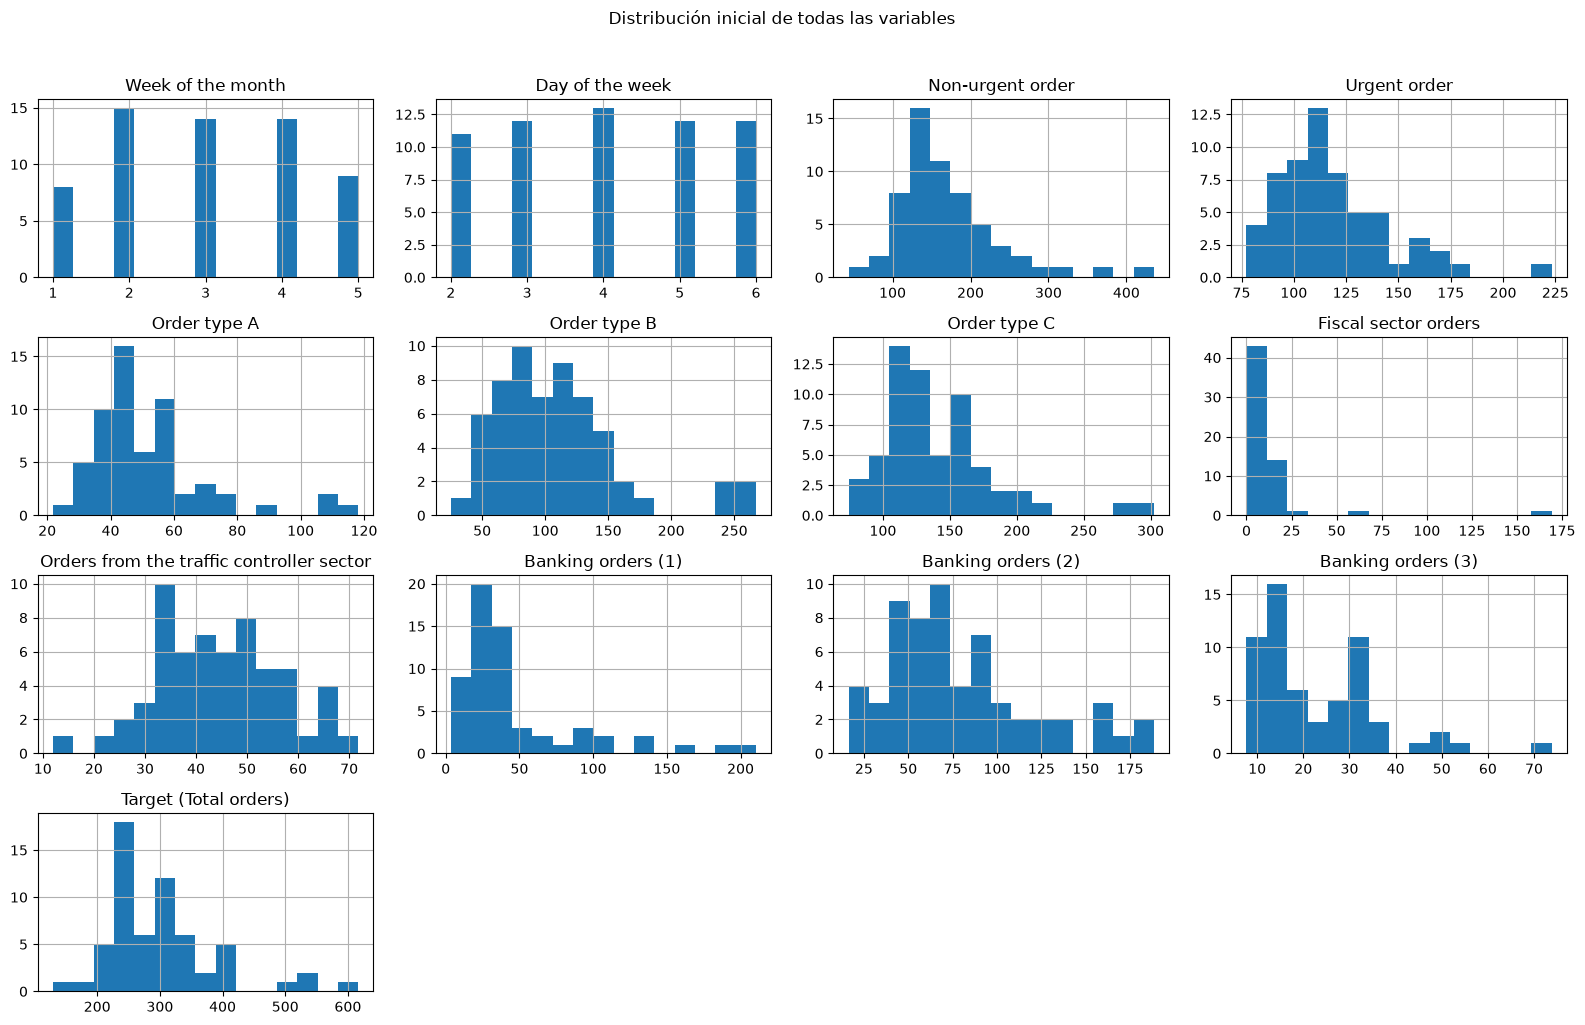

In [12]:
df.hist(bins=15, figsize=(16, 10))                                    # Dibuja un histograma de 15 barras para cada columna numérica
plt.suptitle("Distribución inicial de todas las variables", y=1.02)   # Agrega un título general arriba de toda la figura
plt.tight_layout()                                                    # Ajusta automáticamente los espacios para que no se encimen los textos
plt.show()                                                            # Renderiza la gráfica en pantalla

#### Interpretación de las estadísticas descriptivas

**1. Las escalas son muy distintas.** Las variables se agrupan en tres órdenes de magnitud:

| Grupo | Variables | Valores típicos |
|---|---|---|
| Calendario | `Week of the month`, `Day of the week` | 1 a 6 |
| Pedidos por tipo y sector fiscal | `Non-urgent`, `Urgent`, `Order type A/B/C`, `Fiscal sector`, Target | decenas a cientos (máx. 865) |
| Tráfico y bancarios | `Traffic controller`, `Banking orders (1)`, `(2)`, `(3)` | miles a cientos de miles (máx. 210 508) |

Por ejemplo, `Banking orders (2)` tiene una desviación estándar de unos 40 500, mientras que la de `Urgent order` es de 27 y la de `Day of the week` de 1.4. Esto **justifica el escalado** (pregunta 4):

- En el **gradiente descendente**, las variables con valores enormes producen gradientes enormes; sin escalar, la tasa de aprendizaje que sirve para una variable hace diverger a otra, y el algoritmo converge muy lento o no converge.
- En **Ridge y Lasso**, la penalización actúa sobre el tamaño de los coeficientes; si las variables están en escalas distintas, se penaliza más a unas que a otras sin razón.
- La **Ecuación Normal** y `LinearRegression` no necesitan escalado para encontrar la solución, pero escalar facilita comparar los coeficientes entre sí.

Por eso, antes de entrenar se aplicará `StandardScaler` (media 0 y desviación 1), ajustado solo con los datos de entrenamiento.

**2. Algunas variables están muy sesgadas.** Cuando la media es mucho mayor que la mediana, unos pocos valores muy altos tiran del promedio hacia arriba:

- `Fiscal sector orders`: media 77.4, pero mediana 7.8 y máximo 865. La desviación (186.5) es más del doble de la media. La mayoría de los días tiene pocos o ningún pedido fiscal, y unos pocos días tienen muchísimos.
- `Banking orders (1)`: media 46 641 frente a mediana 32 528, con máximo de 210 508.

Estos valores extremos se analizan en la sección de outliers.

**3. El Target** va de 129 a 616 pedidos diarios, con media 301 y mediana 288: tiene una ligera cola hacia valores altos.

### 1.4 Correlación entre variables

Se calcula la **correlación de Pearson** entre todos los pares de variables y se muestra en un mapa de calor. El coeficiente va de −1 a 1: cerca de 1 indica que dos variables suben juntas, cerca de −1 que una sube cuando la otra baja, y cerca de 0 que no hay relación lineal.

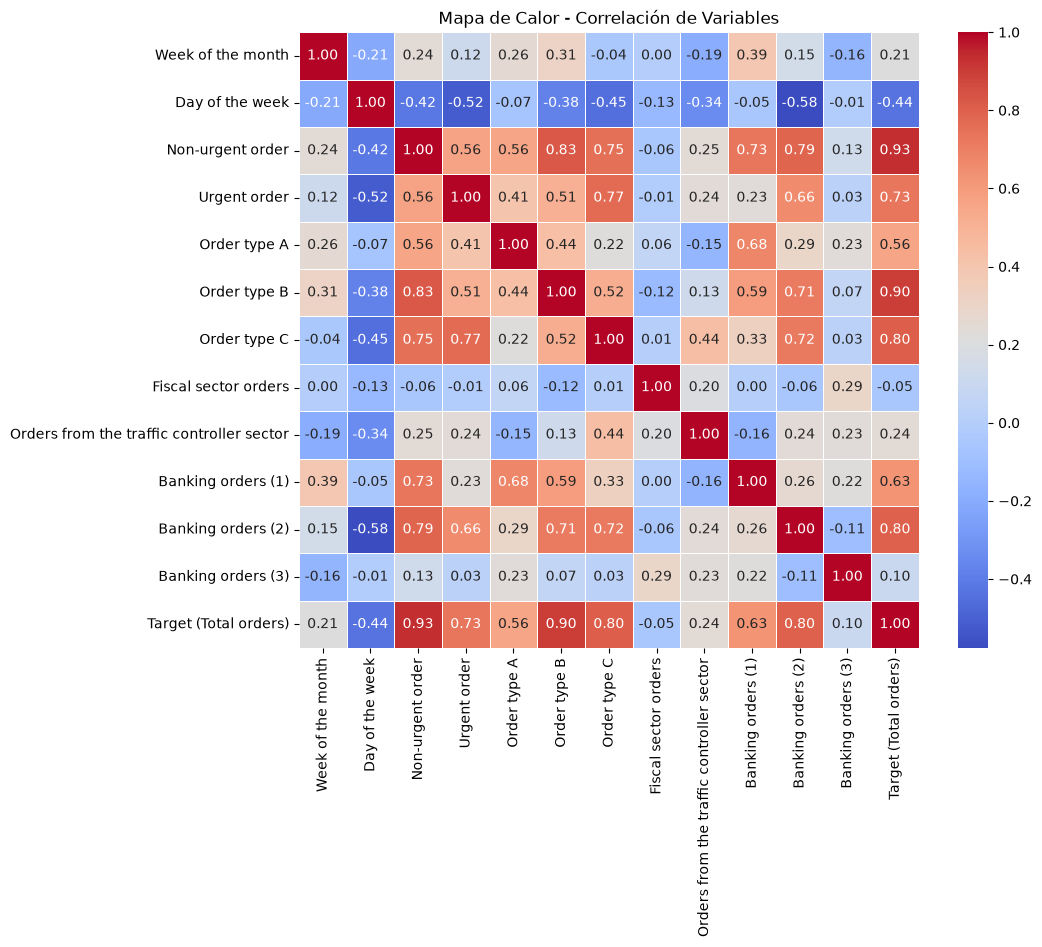

In [7]:
# Crea una figura de 10 x 8 pulgadas (tamaño suficiente para leer los 13 x 13 números)
plt.figure(figsize=(10, 8))

# df.corr() calcula la correlación de Pearson entre cada par de columnas -> matriz 13 x 13
# sns.heatmap la dibuja como cuadrícula de colores:
#   annot=True       -> escribe el número dentro de cada casilla
#   cmap="coolwarm"  -> rojo = correlación positiva, azul = negativa, blanco = cercana a 0
#   fmt=".2f"        -> muestra los números con 2 decimales
#   linewidths=0.5   -> líneas finas entre casillas para separarlas
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Mapa de Calor - Correlación de Variables")
plt.show()  # Muestra la gráfica

#### Interpretación del mapa de calor

El mapa de calor muestra la correlación de Pearson entre todas las variables. Además de la relación con el Target (última fila), deja ver que **varios predictores están muy correlacionados entre sí** (multicolinealidad):

| Par de variables | r |
|---|---|
| Non-urgent order – Order type B | 0.83 |
| Non-urgent order – Banking orders (2) | 0.79 |
| Urgent order – Order type C | 0.77 |
| Non-urgent order – Order type C | 0.75 |
| Non-urgent order – Banking orders (1) | 0.73 |

Esto tiene sentido: urgentes/no urgentes y tipos A, B y C son distintas formas de desglosar los mismos pedidos del día, y los pedidos bancarios también suben en los días de mucha demanda. La multicolinealidad no impide ajustar una regresión lineal, pero hace que los coeficientes sean inestables y difíciles de interpretar. Por eso más adelante se usarán **Ridge** y **Lasso**, que penalizan los coeficientes grandes.

También se observa que `Day of the week` tiene correlación negativa con varias variables de pedidos (por ejemplo −0.58 con Banking orders (2)): al avanzar la semana bajan los pedidos.

#### Correlación de cada variable con el Target

Se extrae del mapa de calor solo la columna del Target, se ordena de mayor a menor y se grafica en barras para comparar fácilmente qué variables están más relacionadas con el total de pedidos.

In [8]:
# Nombre de la variable que se quiere predecir
target = "Target (Total orders)"
s
# Correlación de cada predictora con el Target, paso a paso:
#   df.corr(numeric_only=True) -> matriz de correlación completa (solo columnas numéricas)
#   [target]                   -> se queda solo con la columna del Target
#   .drop(target)              -> quita la correlación del Target consigo mismo (siempre es 1)
#   .sort_values(...)          -> ordena de mayor a menor correlación
correlaciones = (
    df.corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(ascending=False)
)

# Muestra la lista con los valores exactos
display(correlaciones)

# Gráfica de barras horizontales: una barra por variable, su largo es la correlación
plt.figure(figsize=(10, 6))
sns.barplot(x=correlaciones.values, y=correlaciones.index)
plt.title("Correlación de las variables con el total de pedidos")
plt.xlabel("Coeficiente de correlación de Pearson")
plt.ylabel("Variable")

# Línea vertical en 0: barras a la derecha = relación positiva, a la izquierda = negativa
plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()  # Ajusta márgenes para que los nombres largos no se corten
plt.show()

NameError: name 's' is not defined

##### Interpretación de la correlación con el Target

Agrupando las variables según la fuerza de su relación lineal con el total de pedidos:

- **Relación fuerte (|r| ≥ 0.7):** `Non-urgent order` (0.93), `Order type B` (0.90), `Order type C` (0.80), `Banking orders (2)` (0.80) y `Urgent order` (0.73). Son las mejores candidatas para predecir el total.
- **Relación moderada:** `Banking orders (1)` (0.63), `Order type A` (0.56) y `Day of the week` (−0.44). Esta última es **negativa**: el lunes se registran en promedio unos 390 pedidos y el viernes unos 263.
- **Relación débil o nula:** `Orders from the traffic controller sector` (0.24), `Week of the month` (0.21), `Banking orders (3)` (0.10) y `Fiscal sector orders` (−0.05). Casi no aportan información lineal sobre el Target. En el caso del sector de tráfico, la correlación de Spearman (basada en rangos) es apenas 0.05, lo que indica que su 0.24 depende de unos pocos valores extremos.

Ojo: que `Order type A`, `B` y `C` aparezcan tan arriba no significa que sean buenos predictores. Como se verifica en la siguiente sección, su suma es exactamente el Target, así que usarlas sería hacer trampa.

#### Diagramas de dispersión

El coeficiente de correlación resume la relación en un solo número, pero no muestra su forma. Por eso se grafica cada predictora contra el Target, con su recta de regresión (en rojo), para ver si la relación es realmente lineal, qué tan dispersos están los puntos y si hay valores atípicos. Se incluyen variables con correlación alta, media y baja; las de tipo de pedido (A, B y C) se dejan por fuera por la fuga de información que se analiza más adelante.

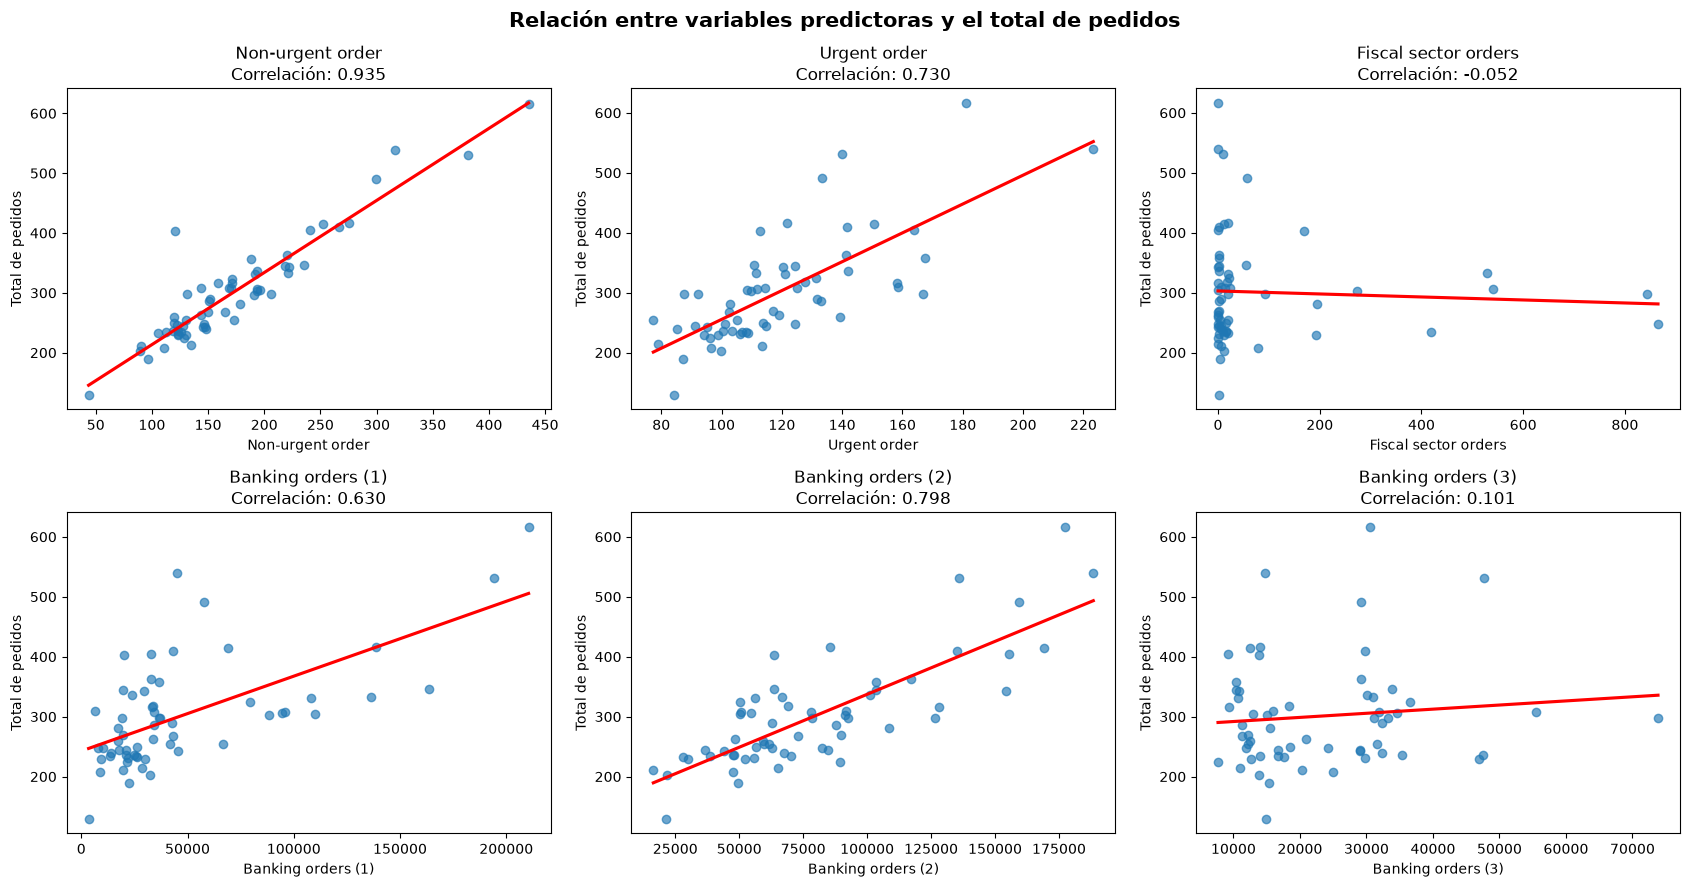

In [ ]:
# Variable objetivo (eje Y de todas las gráficas)
objetivo = "Target (Total orders)"

# Variables predictoras a graficar (eje X): se eligieron con correlación alta, media y baja
# para comparar cómo se ve una relación fuerte frente a una débil
variables = [
    "Non-urgent order",
    "Urgent order",
    "Fiscal sector orders",
    "Banking orders (1)",
    "Banking orders (2)",
    "Banking orders (3)"
]

# Crea una cuadrícula de 2 filas x 3 columnas = 6 gráficas.
# fig es la figura completa; axes contiene los 6 espacios donde se dibuja cada gráfica
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

# axes.flatten() convierte la cuadrícula 2x3 en una lista de 6 espacios.
# zip() empareja cada espacio con una variable: (espacio1, variable1), (espacio2, variable2)...
for ax, variable in zip(axes.flatten(), variables):

    # regplot dibuja los puntos (un punto por día) y la recta de regresión que mejor se ajusta
    sns.regplot(
        data=df,
        x=variable,                       # Predictora en el eje X
        y=objetivo,                       # Total de pedidos en el eje Y
        ax=ax,                            # Dibuja en el espacio que le toca
        scatter_kws={"alpha": 0.65},      # Puntos semitransparentes para ver dónde se acumulan
        line_kws={"color": "red"},        # Recta de regresión en rojo
        ci=None                           # Sin banda de confianza, para una gráfica más limpia
    )

    # Correlación de Pearson entre esta variable y el Target, para ponerla en el título
    correlacion = df[variable].corr(df[objetivo])

    # Título con el nombre de la variable y su correlación con 3 decimales
    ax.set_title(
        f"{variable}\nCorrelación: {correlacion:.3f}"
    )
    ax.set_xlabel(variable)
    ax.set_ylabel("Total de pedidos")

# Título general sobre las 6 gráficas
plt.suptitle(
    "Relación entre variables predictoras y el total de pedidos",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()  # Evita que títulos y ejes se encimen
plt.show()

##### Interpretación de los diagramas de dispersión

Los diagramas confirman lo que dicen los coeficientes:

- **`Non-urgent order`**: los puntos siguen de cerca la recta, con poca dispersión. Es la relación lineal más clara.
- **`Urgent order`** y **`Banking orders (2)`**: tendencia creciente evidente, pero con más dispersión alrededor de la recta.
- **`Banking orders (1)`**: relación positiva más débil; la mayoría de los puntos están concentrados en valores bajos y unos pocos días con valores altos influyen bastante en la pendiente.
- **`Fiscal sector orders`** y **`Banking orders (3)`**: la recta es casi horizontal y los puntos forman una nube sin patrón. En `Fiscal sector orders` se ve además una franja vertical en 0: hay 13 días sin pedidos del sector fiscal.

**Conclusión parcial:** `Non-urgent order`, `Urgent order`, `Banking orders (2)` y `Banking orders (1)` muestran una relación lineal útil con el Target, junto con `Day of the week`. `Fiscal sector orders`, `Banking orders (3)` y el sector de tráfico aportan poco. La selección final de variables se hace después de revisar la fuga de información y los outliers.